# Storybook agent

**Step 1 (terminal, once):** pull + save the data
```
poetry run python scripts/dump_repo_context.py <repo_id>
```

In [31]:
import glob
import json
import asyncio
from pathlib import Path


# --- Load the most recently saved repo_context_*.json ---
NOTEBOOKS = Path("notebooks") if (Path("notebooks") / "data").exists() else Path(".")
files = sorted(
    glob.glob(str(NOTEBOOKS / "data" / "repo_context_*.json")),
    key=lambda p: Path(p).stat().st_mtime,
    reverse=True,
)
if not files:
    raise FileNotFoundError(
        "No repo_context_*.json found. Run first:\n"
        "  poetry run python scripts/dump_repo_context.py <repo_id>"
    )

# Or pin a specific file: DATA_PATH = NOTEBOOKS / "data" / "repo_context_<id>.json"
DATA_PATH = Path(files[0])
print(f"Loading: {DATA_PATH}")
context = json.loads(DATA_PATH.read_text())
context["__data_path__"] = str(DATA_PATH)

Loading: data/repo_context_743b88e2-f981-4930-95b5-a0c9359f5b2e.json


In [32]:
from typing import Optional
from pydantic import BaseModel, Field


class GraphNode(BaseModel):
    id: str
    label: str
    node_type: str
    file_path: Optional[str] = None
    file_id: Optional[str] = None
    line_start: Optional[int] = None
    line_end: Optional[int] = None
    is_async: bool = False
    source_code: Optional[str] = None
    symbol_type: Optional[str] = None
    return_type: Optional[str] = None
    parameters: Optional[str] = None
    docstring: Optional[str] = None


class GraphEdge(BaseModel):
    source: str
    target: str
    edge_type: str
    call_line: Optional[int] = None
    weight: int = 1


class OverviewStats(BaseModel):
    files: int = 0
    folders: int = 0
    functions: int = 0
    dependencies: int = 0


class RepoContext(BaseModel):
    connected_repo_id: str
    repo_id: Optional[str] = None
    full_name: Optional[str] = None
    default_branch: Optional[str] = None
    language: Optional[str] = None
    description: Optional[str] = None
    overview_stats: OverviewStats = OverviewStats()
    file_nodes: list[GraphNode] = Field(default_factory=list)
    file_edges: list[GraphEdge] = Field(default_factory=list)
    function_nodes: list[GraphNode] = Field(default_factory=list)
    function_edges: list[GraphEdge] = Field(default_factory=list)


# Typed view of the loaded JSON (drops the __data_path__ helper key)
ctx = RepoContext(**{k: v for k, v in context.items() if k != "__data_path__"})

In [33]:
s = ctx.overview_stats
print(f"Repo       : {ctx.full_name} ({ctx.connected_repo_id})")
print(f"Language   : {ctx.language}")
print(f"Branch     : {ctx.default_branch}")
print("---")
print(f"Files      : {s.files}")
print(f"Folders    : {s.folders}")
print(f"Functions  : {s.functions}")
print(f"File deps  : {s.dependencies}")
print(f"Call edges : {len(ctx.function_edges)}")

Repo       : macphailmagwira/ramp (743b88e2-f981-4930-95b5-a0c9359f5b2e)
Language   : Python
Branch     : main
---
Files      : 200
Folders    : 55
Functions  : 464
File deps  : 131
Call edges : 295


In [34]:
# --- Inspect a sample function node (with source code) ---
if ctx.function_nodes:
    fn = ctx.function_nodes[0]
    print(f"Function: {fn.label}  ({fn.node_type})  async={fn.is_async}")
    print(f"File     : {fn.file_path}:{fn.line_start}-{fn.line_end}")
    print("Source:")
    print(fn.source_code or "(no source captured)")

Function: health_check  (function)  async=True
File     : src/common/router.py:17-24
Source:
async def health_check(request: Request):
    return {
        "status": "healthy",
        "timestamp": datetime.now().isoformat(),
        "service": "api-main",
        "version": "0.1.0",
        "environment": "DEV",
    }


In [35]:
# --- Processing example: prepare inputs for the story/flow agent ---
# Builds the function_nodes (+source) + function_edges payload the AI
# services consume, plus a couple of derived views.

flow_nodes = [
    {
        "id": n.id,
        "label": n.label,
        "node_type": n.node_type,
        "file_path": n.file_path,
        "is_async": n.is_async,
        "line_start": n.line_start,
        "source_code": n.source_code,
    }
    for n in ctx.function_nodes
]
flow_edges = [
    {"source": e.source, "target": e.target, "edge_type": e.edge_type}
    for e in ctx.function_edges
]

async_fns = [n.label for n in ctx.function_nodes if n.is_async]
by_file: dict[str, int] = {}
for n in ctx.function_nodes:
    if n.file_path:
        by_file[n.file_path] = by_file.get(n.file_path, 0) + 1

print(f"Async functions ({len(async_fns)}): {async_fns[:10]}")
print("\nFunctions per file (top 10):")
for path, count in sorted(by_file.items(), key=lambda kv: kv[1], reverse=True)[:10]:
    print(f"  {count:3d}  {path}")

print(f"\nPrepared flow_nodes={len(flow_nodes)} flow_edges={len(flow_edges)}")
# `flow_nodes` + `flow_edges` are now ready to pass into the LangGraph agent.

Async functions (161): ['health_check', 'run_async_migrations', 'BaseRepository.create', 'BaseRepository.update', 'BaseRepository.delete', 'BaseRepository.filter', 'BaseRepository.get_by_id', 'BaseRepository.get_all', 'generic_exception_handler', 'protected_route']

Functions per file (top 10):
   94  tests/conftest.py
   26  src/features/github/services/service.py
   25  src/features/github/schema.py
   23  src/features/github/repository.py
   19  terraform/modules/appsync/generate-from-openapi.js
   17  src/features/github/router.py
   14  src/features/ai/schema.py
   11  src/features/ai/service.py
   11  src/features/github/services/symbol_extractor.py
   11  src/features/user/service.py

Prepared flow_nodes=464 flow_edges=295


## Cell 1: imports, config, shared LLM helper

In [36]:
# Shared LLM helpers (call_qwen / parse_json) now live in the package
# (src.features.ai.bedrock). Only the imports the inline parent graph still
# needs are kept here.
import sys, os
sys.path.insert(0, os.path.abspath(".."))  # repo root (notebook runs from notebooks/)
from langgraph.graph import StateGraph, START, END
from src.features.storybook.agent.story_book_agent import OUTPUT_DIR


In [37]:
# SETUP subgraph is now imported from the package (registry cell below).
# The old inline definition was removed to avoid duplicating
# src.features.storybook.agent.setup.


## Cell 3: registry (add new subgraphs here)

In [38]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))  # repo root (notebook runs from notebooks/)
from src.features.storybook.agent.setup import SETUP_NAME, build_setup
from src.features.storybook.agent.learn import LEARN_NAME, build_learn

SUBGRAPHS = [
    (SETUP_NAME, build_setup),
    (LEARN_NAME, build_learn),
    # (BUILD_NAME, build_build),   # later
]


## Cell 4: parent graph

In [39]:
# Parent graph (build_parent / generate_storybook / GRAPH) now comes from the package,
# so the notebook no longer duplicates src.features.storybook.agent.story_book_agent.
from src.features.storybook.agent.story_book_agent import generate_storybook, GRAPH, build_parent


## Cell 5: run it (use await, not asyncio.run, because Jupyter already has an event loop)

In [40]:
book = await generate_storybook("..")
print(json.dumps(book, indent=2))

{
  "project": "ramp",
  "sections": {
    "set_up": {
      "schema_version": 1,
      "summary": "The project can be started using Docker Compose configurations for development, local, staging, and production environments, or via Makefile targets and manual Python-based execution, with Docker Compose being the most reliable method.",
      "env_vars": [
        {
          "name": "ENVIRONMENT",
          "purpose": "Determines configuration behavior (DEVELOPMENT, STAGING, PRODUCTION); used in entrypoint.sh and gunicorn.conf.py to set log levels and settings."
        },
        {
          "name": "POSTGRES_USER",
          "purpose": "PostgreSQL username for database access; defined in docker-compose files and loaded from .env."
        },
        {
          "name": "POSTGRES_PASSWORD",
          "purpose": "PostgreSQL password for database authentication; defined in docker-compose files and loaded from .env."
        },
        {
          "name": "POSTGRES_DB",
          "purpos

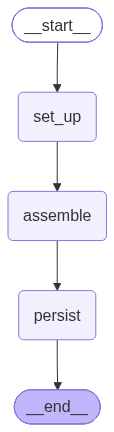

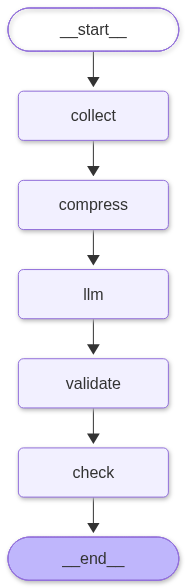

In [41]:
from IPython.display import Image, display

display(Image(GRAPH.get_graph().draw_mermaid_png()))


#setup subgraph
display(Image(build_setup().get_graph().draw_mermaid_png()))


